# Task 51: Manual Neural-Network Learning-Rate Scheduler

Implement a reduce-on-validation-plateau schedule by hand and inspect learning rate, training/validation loss, and cumulative parameter-update norms by epoch.

Constant LR test: {'accuracy': np.float64(0.6721311475409836), 'precision': np.float64(0.6756756756756757), 'recall': np.float64(0.7575757575757576), 'f1': np.float64(0.7142857142857142)}
Scheduled LR test: {'accuracy': np.float64(0.6721311475409836), 'precision': np.float64(0.6756756756756757), 'recall': np.float64(0.7575757575757576), 'f1': np.float64(0.7142857142857142)}
Manual scheduler events: [{'epoch': 47, 'new_rate': 0.01, 'validation_loss': 0.43431362448320693}, {'epoch': 58, 'new_rate': 0.005, 'validation_loss': 0.41888053244835816}, {'epoch': 66, 'new_rate': 0.0025, 'validation_loss': 0.42195032340012295}, {'epoch': 76, 'new_rate': 0.00125, 'validation_loss': 0.41832732003698725}, {'epoch': 82, 'new_rate': 0.000625, 'validation_loss': 0.43033236861819857}, {'epoch': 88, 'new_rate': 0.0005, 'validation_loss': 0.41722592675382836}]


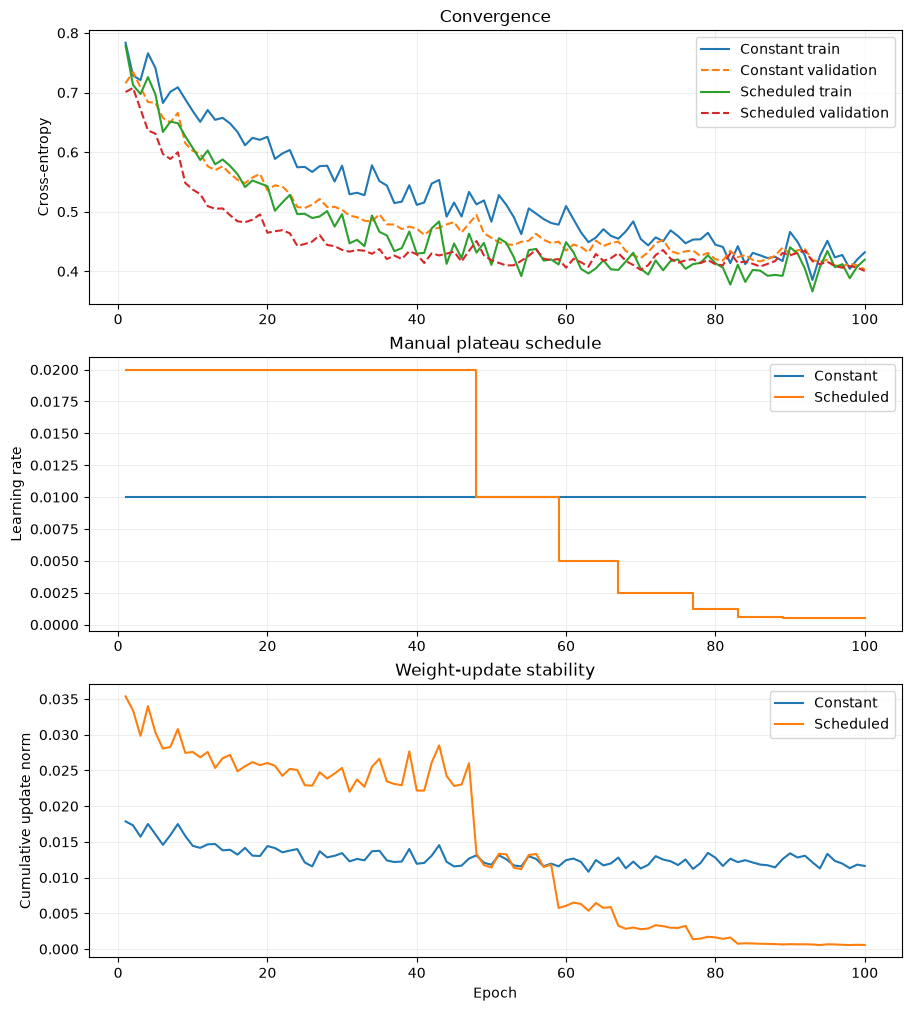

Rate reductions follow validation plateaus; smaller update norms indicate smaller cumulative weight changes, not guaranteed generalization.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths=[Path('heart.csv'),Path('Task_51_Manual_Neural_Learning_Rate_Scheduler/heart.csv'),Path('Heart_Disease_Tasks/Task_51_Manual_Neural_Learning_Rate_Scheduler/heart.csv')]
data=pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features=[c for c in ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal'] if c in data]
X,y=data[features].to_numpy(float),data.target.to_numpy(int)

def split(labels,fraction,seed):
    rng=np.random.default_rng(seed);a=[];b=[]
    for label in np.unique(labels):
        ids=np.flatnonzero(labels==label);rng.shuffle(ids);cut=round(fraction*len(ids));a.extend(ids[:cut]);b.extend(ids[cut:])
    rng.shuffle(a);rng.shuffle(b);return np.array(a),np.array(b)
trainval,test=split(y,.8,51);trlocal,vlocal=split(y[trainval],.8,52);train,val=trainval[trlocal],trainval[vlocal]
Xtr,Xv,Xte=X[train],X[val],X[test];ytr,yv,yte=y[train],y[val],y[test]
mean,scale=Xtr.mean(0),Xtr.std(0);scale[scale==0]=1
Xtr,Xv,Xte=(Xtr-mean)/scale,(Xv-mean)/scale,(Xte-mean)/scale

def sigmoid(z):return 1/(1+np.exp(-np.clip(z,-35,35)))
class ScratchMLP:
    def __init__(self,hidden=(24,12),rate=.01,seed=51):self.hidden,self.rate,self.seed=hidden,rate,seed
    def fit(self,x,y,xv,yv,epochs=100,batch=32,dropout=.15,scheduler=None):
        rng=np.random.default_rng(self.seed);dims=(x.shape[1],*self.hidden,1)
        self.w=[rng.normal(0,np.sqrt(2/dims[i]),(dims[i],dims[i+1])) for i in range(len(dims)-1)]
        self.b=[np.zeros((1,dims[i+1])) for i in range(len(dims)-1)];h=len(self.hidden)
        self.gamma=[np.ones((1,k)) for k in self.hidden];self.beta=[np.zeros((1,k)) for k in self.hidden]
        self.running_mean=[np.zeros((1,k)) for k in self.hidden];self.running_var=[np.ones((1,k)) for k in self.hidden]
        self.train_loss=[];self.validation_loss=[];self.rates=[];self.update_norm=[];self.events=[]
        patience=int(scheduler.get('patience',6)) if scheduler else 6
        factor=float(scheduler.get('factor',.5)) if scheduler else .5
        min_delta=float(scheduler.get('min_delta',.0005)) if scheduler else .0005
        min_rate=float(scheduler.get('min_rate',.0005)) if scheduler else .0005
        best=np.inf;stale=0
        for epoch in range(epochs):
            rate=self.rate;total_loss=0.;update_sq=0.;order=rng.permutation(len(x))
            for start in range(0,len(x),batch):
                ids=order[start:start+batch];xb=x[ids];yb=y[ids,None].astype(float);acts=[xb];cache=[]
                for layer in range(h):
                    z=acts[-1]@self.w[layer]+self.b[layer];mu=z.mean(0,keepdims=True);var=z.var(0,keepdims=True)
                    inv=1/np.sqrt(var+1e-5);norm=(z-mu)*inv;scaled=self.gamma[layer]*norm+self.beta[layer]
                    self.running_mean[layer]=.9*self.running_mean[layer]+.1*mu;self.running_var[layer]=.9*self.running_var[layer]+.1*var
                    activation=np.maximum(scaled,0);mask=(rng.random(activation.shape)>=dropout).astype(float)/(1-dropout) if dropout and len(ids)>1 else None
                    if mask is not None:activation*=mask
                    cache.append((norm,inv,scaled,mask));acts.append(activation)
                p=sigmoid(acts[-1]@self.w[-1]+self.b[-1]);total_loss+=float(-np.sum(yb*np.log(p+1e-12)+(1-yb)*np.log(1-p+1e-12)))
                grad=(p-yb)/len(ids);dw=[None]*len(self.w);db=[None]*len(self.b);dg=[None]*h;dbe=[None]*h
                dw[-1]=acts[-1].T@grad;db[-1]=grad.sum(0,keepdims=True);grad=grad@self.w[-1].T
                for layer in range(h-1,-1,-1):
                    norm,inv,scaled,mask=cache[layer]
                    if mask is not None:grad*=mask
                    grad*=scaled>0;dg[layer]=np.sum(grad*norm,0,keepdims=True);dbe[layer]=grad.sum(0,keepdims=True)
                    dn=grad*self.gamma[layer];grad=inv/len(ids)*(len(ids)*dn-dn.sum(0,keepdims=True)-norm*np.sum(dn*norm,0,keepdims=True))
                    dw[layer]=acts[layer].T@grad;db[layer]=grad.sum(0,keepdims=True);grad=grad@self.w[layer].T
                for layer in range(len(self.w)):
                    update_w=rate*dw[layer];update_b=rate*db[layer];update_sq+=float(np.sum(update_w**2)+np.sum(update_b**2))
                    self.w[layer]-=update_w;self.b[layer]-=update_b
                for layer in range(h):
                    update_g=rate*dg[layer];update_beta=rate*dbe[layer];update_sq+=float(np.sum(update_g**2)+np.sum(update_beta**2))
                    self.gamma[layer]-=update_g;self.beta[layer]-=update_beta
            self.train_loss.append(total_loss/len(x));self.rates.append(rate);self.update_norm.append(float(np.sqrt(update_sq)))
            self.validation_loss.append(self.loss(xv,yv))
            if scheduler:
                if self.validation_loss[-1]<best-min_delta:best=self.validation_loss[-1];stale=0
                else:stale+=1
                if stale>=patience:
                    next_rate=max(min_rate,self.rate*factor)
                    if next_rate<self.rate:self.rate=next_rate;self.events.append({'epoch':epoch+1,'new_rate':self.rate,'validation_loss':self.validation_loss[-1]})
                    stale=0
        return self
    def probability(self,x):
        a=x
        for layer in range(len(self.hidden)):
            z=a@self.w[layer]+self.b[layer];z=self.gamma[layer]*((z-self.running_mean[layer])/np.sqrt(self.running_var[layer]+1e-5))+self.beta[layer];a=np.maximum(z,0)
        return sigmoid(a@self.w[-1]+self.b[-1]).ravel()
    def loss(self,x,y):
        p=np.clip(self.probability(x),1e-12,1-1e-12);return float(-np.mean(y*np.log(p)+(1-y)*np.log(1-p)))

baseline=ScratchMLP(rate=.01,seed=51).fit(Xtr,ytr,Xv,yv,epochs=100)
scheduled=ScratchMLP(rate=.02,seed=51).fit(Xtr,ytr,Xv,yv,epochs=100,scheduler={'factor':.5,'patience':6,'min_delta':.0005,'min_rate':.0005})
def metric(ytrue,pred):
    tp=np.sum((ytrue==1)&(pred==1));tn=np.sum((ytrue==0)&(pred==0));fp=np.sum((ytrue==0)&(pred==1));fn=np.sum((ytrue==1)&(pred==0))
    p=tp/(tp+fp) if tp+fp else 0.;r=tp/(tp+fn) if tp+fn else 0.
    return {'accuracy':(tp+tn)/len(ytrue),'precision':p,'recall':r,'f1':2*p*r/(p+r) if p+r else 0.}
print('Constant LR test:',metric(yte,(baseline.probability(Xte)>=.5).astype(int)))
print('Scheduled LR test:',metric(yte,(scheduled.probability(Xte)>=.5).astype(int)))
print('Manual scheduler events:',scheduled.events)
fig,axes=plt.subplots(3,1,figsize=(9,10),constrained_layout=True);epochs=np.arange(1,101)
for name,model in [('Constant',baseline),('Scheduled',scheduled)]:
    axes[0].plot(epochs,model.train_loss,label=f'{name} train');axes[0].plot(epochs,model.validation_loss,linestyle='--',label=f'{name} validation')
    axes[1].step(epochs,model.rates,where='post',label=name);axes[2].plot(epochs,model.update_norm,label=name)
axes[0].set_ylabel('Cross-entropy');axes[0].set_title('Convergence');axes[0].legend();axes[0].grid(alpha=.2)
axes[1].set_ylabel('Learning rate');axes[1].set_title('Manual plateau schedule');axes[1].legend();axes[1].grid(alpha=.2)
axes[2].set_xlabel('Epoch');axes[2].set_ylabel('Cumulative update norm');axes[2].set_title('Weight-update stability');axes[2].legend();axes[2].grid(alpha=.2);plt.show()
print('Rate reductions follow validation plateaus; smaller update norms indicate smaller cumulative weight changes, not guaranteed generalization.')